# 99 - Tổng hợp: chọn model nào?

Gom kết quả của tất cả các notebook trước. **Điểm chất lượng** = trung bình các bài đo trên ĐÚNG file GGUF của cấu hình đó (tool calling native, BFCL, faithfulness). Điểm kiến thức/toán/safety (notebook 01/02/06) đo trên trọng số HF gốc nên chỉ hiện để tham khảo, không tính vào quality. Sau đó lọc theo điều kiện thực tế của board: vừa RAM và trả lời kịp thời gian.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd

In [ ]:
# Điểm đo trên ĐÚNG file GGUF của từng cấu hình -> dùng để tính "quality" và so sánh mức nén.
quant_parts = {"tools": ("tool_calling", "native_acc_all"), "bfcl": ("bfcl", "overall"),
               "faithful": ("faithfulness", "overall")}
# Điểm đo trên trọng số HF GỐC (notebook 01/02/06) -> CHỈ để tham khảo, KHÔNG tính vào quality,
# vì nếu ghép vào hàng Q4/Q8 thì bản nén sẽ được "mượn" điểm của bản gốc.
base_parts = {"general_hf": ("general_knowledge", "average"), "reasoning_hf": ("reasoning", "gsm8k"),
              "safety_hf": ("safety", "average")}

summary = st.load("performance")[["id", "model", "quant", "label", "params_b", "ram_peak_mb", "total_p95_s"]]
for col, (file, metric) in quant_parts.items():          # đo theo từng quant: ghép theo id
    d = st.load(file)
    if metric not in d and file == "tool_calling" and "acc_all" in d:
        metric = "acc_all"                                 # kết quả cũ chưa có native
        print("CHÚ Ý: tool_calling chưa có native_acc_all, tạm dùng acc_all (định dạng cũ, xem notebook 03)")
    if metric in d:
        summary = summary.merge(d[["id", metric]].rename(columns={metric: col}), on="id", how="left")
for col, (file, metric) in base_parts.items():           # đo trên model gốc: ghép theo model, chỉ tham khảo
    d = st.load_base(file)
    if metric in d:
        summary = summary.merge(d[["model", metric]].rename(columns={metric: col}), on="model", how="left")

score_cols = [c for c in quant_parts if c in summary]
summary["quality"] = summary[score_cols].mean(axis=1)
summary["fits"] = (summary.ram_peak_mb <= st.RAM_BUDGET_MB) & (summary.total_p95_s <= st.TTL_S)
summary.sort_values("quality", ascending=False).round(3)

## Biểu đồ 1 - Bảng điểm tổng hợp

In [ ]:
cols = {"tools": "Our tool\ntest", "bfcl": "BFCL", "faithful": "Faithful",
        "general_hf": "General\n(HF base)", "reasoning_hf": "Math\n(HF base)", "safety_hf": "Honesty\n(HF base)"}
st.heatmap(summary, {c: t for c, t in cols.items() if c in summary}, "Scoreboard",
           "Darker = better. Sorted by average. '(HF base)' = original weights, same value for every quant of a model",
           name="99_scoreboard")

## Biểu đồ 2 - Chất lượng so với RAM: model nào đáng chọn?

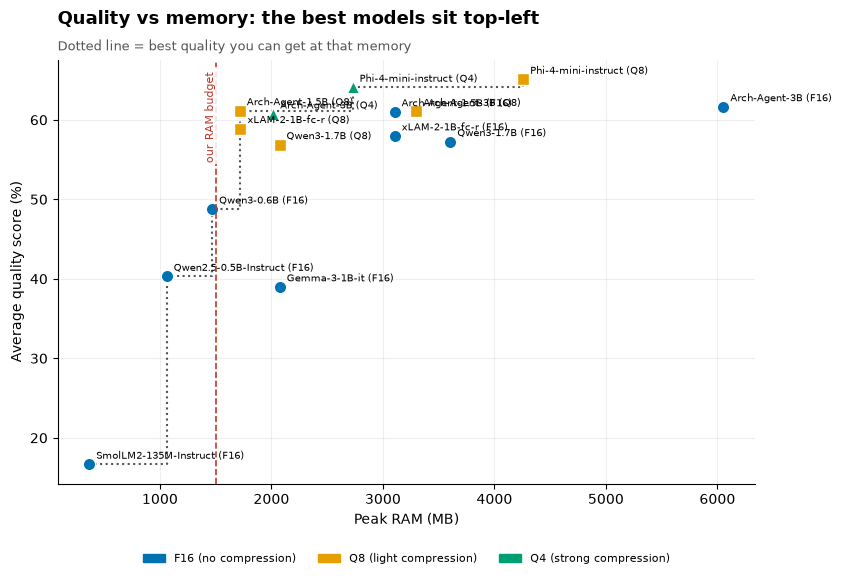

In [4]:
st.scatter_chart(summary, "ram_peak_mb", "quality", "Quality vs memory: the best models sit top-left",
                 "Peak RAM (MB)", "Average quality score (%)", subtitle="Dotted line = best quality you can get at that memory", lines=[(st.RAM_BUDGET_MB, "our RAM budget")],
                 frontier=True, name="99_quality_vs_ram")

## Biểu đồ 3 - Model lớn đã nén có hơn model nhỏ không nén không?

Trục ngang là kích thước model (số tỉ tham số). Nếu các chấm cam/xanh lá (đã nén) ở bên phải nằm CAO hơn các chấm xanh dương (không nén) ở bên trái thì nén model lớn là đáng.

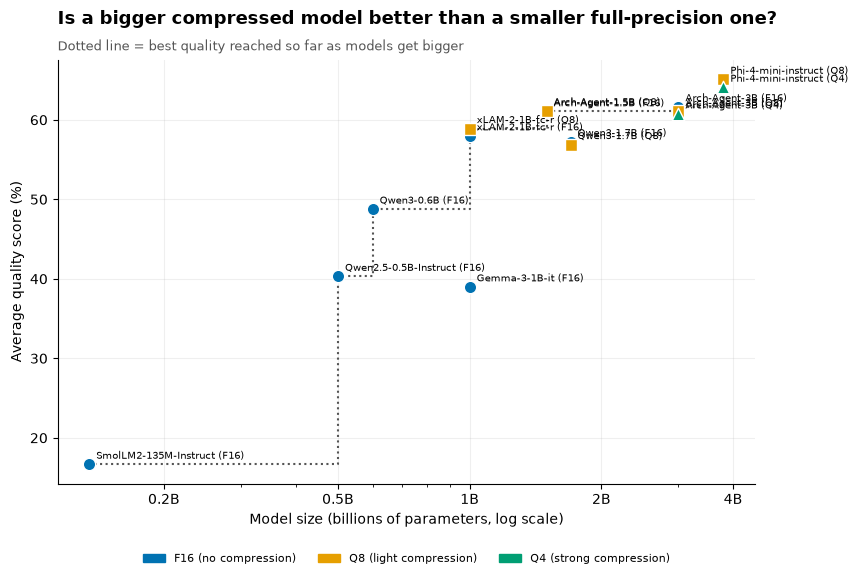

In [5]:
st.scatter_chart(summary, "params_b", "quality", "Is a bigger compressed model better than a smaller full-precision one?",
                 "Model size (billions of parameters, log scale)", "Average quality score (%)", logx=True,
                 subtitle="Dotted line = best quality reached so far as models get bigger",
                 frontier=True, name="99_size_vs_quality")

### Bảng trả lời trực tiếp: với mỗi model lớn đã nén, so với model nhỏ hơn không nén tốt nhất

In [6]:
full = summary[summary.quant == "F16"]
rows = []
for r in summary[summary.quant != "F16"].itertuples():
    smaller = full[full.params_b < r.params_b].dropna(subset=["quality"])
    if len(smaller) and r.quality == r.quality:
        best = smaller.sort_values("quality").iloc[-1]
        rows.append({"compressed bigger model": r.label, "its quality": round(r.quality * 100, 1),
                     "best smaller uncompressed model": best.label, "its quality ": round(best.quality * 100, 1),
                     "bigger compressed wins?": "YES" if r.quality > best.quality else "no"})
pd.DataFrame(rows)

,compressed bigger model,its quality,best smaller uncompressed model,its quality,bigger compressed wins?
0,Arch-Agent-1.5B (Q8),61.1,xLAM-2-1B-fc-r (F16),58.0,YES
1,xLAM-2-1B-fc-r (Q8),58.9,Qwen3-0.6B (F16),48.8,YES
2,Qwen3-1.7B (Q8),56.9,Arch-Agent-1.5B (F16),61.0,no
3,Arch-Agent-3B (Q8),61.0,Arch-Agent-1.5B (F16),61.0,YES
4,Phi-4-mini-instruct (Q8),65.1,Arch-Agent-3B (F16),61.6,YES
5,Arch-Agent-3B (Q4),60.7,Arch-Agent-1.5B (F16),61.0,no
6,Phi-4-mini-instruct (Q4),64.1,Arch-Agent-3B (F16),61.6,YES


Nhớ: số RAM và thời gian chỉ chính thức khi đo trên UNO Q. Nếu danh sách trên rỗng, nới `st.RAM_BUDGET_MB` hoặc xem model nhỏ nhất có đạt chất lượng tối thiểu không.